# Welcome to the Quantum Trojan Challenge

One forensic investigation spans six intercepted quantum jobs. Recover each
job's persistent measurement-mask key and explain the conditional behavior
injected into its circuit.

You receive **a circuit and 8,192 masked measurement shots for each case**.
Cases are named `circuit1` through `circuit6`.  Each case has an independent key.

| Challenge | Evidence | Required work | Points |
| --- | --- | --- | --- |
| Silent Witness — six circuit cases | QASM circuits and measurement counts | Keys, trigger identification and explanations, recovery code and write-up | 100 |

Follow [setup](docs/setup.md) first, then run cells from top to bottom. No quantum
hardware or remote account is required.


## Background

A fixed XOR mask flips selected measurement bits. Applying the same key again
removes those flips. The key remains fixed over the shots of one job.

Dynamic circuits can measure qubits before execution ends, use classical results
in conditions and reuse physical wires. Some of this behavior can be legitimate, but
some may expose information unintentionally. You must investigate which records
control the injected behavior and what those operations do.

Counts are frequencies: an entry with value 500 represents 500 observations.
Preserve leading zeros and bit order.


## 1. Load the necessary files

The index pairs circuit files with their supplied counts and lists the case settings.


In [1]:
from pathlib import Path
import sys
from importlib.metadata import version

candidates = [Path.cwd(), Path.cwd() / 'quantum_trojan_challenge_multi', *Path.cwd().parents]
ROOT = next((p for p in candidates if (p / 'cases.json').is_file()
             and (p / 'TROJAN_CHALLENGE.ipynb').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Start from the supplied challenge folder.')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from challenge_utils import load_cases, load_counts, project_register_counts, validate_answer

CASES = load_cases(ROOT)
print('Python:', sys.version.split()[0])
print('Qiskit:', version('qiskit'), '| Aer:', version('qiskit-aer'))
for case_id, case in CASES.items():
    print(case_id, '| readout bits:', case['key_bits'], '| supplied shots:', case['shots'])


Python: 3.11.18
Qiskit: 2.6.2 | Aer: 0.18.2
circuit1 | readout bits: 41 | supplied shots: 8192
circuit2 | readout bits: 33 | supplied shots: 8192
circuit3 | readout bits: 41 | supplied shots: 8192
circuit4 | readout bits: 31 | supplied shots: 8192
circuit5 | readout bits: 41 | supplied shots: 8192
circuit6 | readout bits: 35 | supplied shots: 8192


## 2. Select a case and load its evidence

Read the [full brief](challenges/01_silent_witness/README.md). Repeat your
investigation for all six cases, or develop code that handles them together.
You may inspect, modify, simplify and simulate copies of the supplied circuits.


In [2]:
from qiskit import qasm3

CASE_ID = 'circuit1'  # circuit1 ... circuit6
case = CASES[CASE_ID]
circuit = qasm3.loads((ROOT / case['circuit']).read_text())
counts = load_counts(ROOT / case['measurements'])
print('Case:', CASE_ID)
print('Active quantum wires:', circuit.num_qubits)
print('Full classical record width:', circuit.num_clbits)
print('Supplied readout register:', case['readout_register'])
print('Supplied outcome width:', len(next(iter(counts))))
print('Distinct outcomes:', len(counts), '| total shots:', sum(counts.values()))
print('Example (word, frequency):', next(iter(counts.items())))


Case: circuit1
Active quantum wires: 21
Full classical record width: 41
Supplied readout register: c
Supplied outcome width: 41
Distinct outcomes: 6998 | total shots: 8192
Example (word, frequency): ('00000000000101010110111011000000010110110', 1)


## 3. Inspect the circuit and counts

The supplied measurement words and submitted XOR key refer to the final values
of readout register `c`.

For `c`, displayed words run from the highest-index bit down to `c[0]`.
The submitted key must follow that same displayed order. Trigger descriptions
must identify registers and zero-based QASM indices, rather than ambiguous
character positions.

Circuit drawings and histograms can be large. Enable the examples below only
when useful; a plot of the most common words is not the complete distribution.


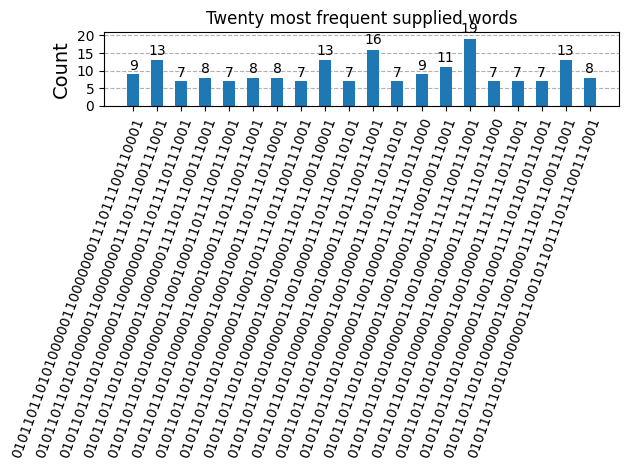

In [4]:
DRAW_CIRCUIT = False
PLOT_COUNTS = True
if DRAW_CIRCUIT:
    print(circuit.draw(output='text', fold=120))
if PLOT_COUNTS:
    from qiskit.visualization import plot_histogram
    most_common = dict(sorted(counts.items(), key=lambda item: item[1], reverse=True)[:20])
    display(plot_histogram(most_common, title='Twenty most frequent supplied words'))


## 4. Optional local simulation

Use the supplied counts as the shared reference. You do not need to regenerate
all 8,192 shots. Large dynamic circuits can take substantial time and memory;
start with a small local batch.

The fixed seed below makes your own experiment repeatable. Exact counts can
differ between sampling algorithms and backend versions even with the same
seed; compare statistical relationships rather than dictionary equality.

Local simulator results and the supplied measurement words both use the final
values of readout register `c`.


In [ ]:
RUN_SIMULATION = False
SIMULATION_SHOTS = 64
SIMULATION_SEED = case['simulation_seed']  # 2026
local_counts = None
if RUN_SIMULATION:
    from qiskit import transpile
    from qiskit_aer import AerSimulator
    simulator = AerSimulator(method='statevector', max_parallel_threads=4,
                             max_parallel_shots=1, max_memory_mb=2048)
    runnable = transpile(circuit, simulator, seed_transpiler=2026)
    full_counts = simulator.run(runnable, shots=SIMULATION_SHOTS,
                                seed_simulator=SIMULATION_SEED).result().get_counts()
    local_counts = project_register_counts(circuit, full_counts, case['readout_register'])
    print('Local shots:', sum(local_counts.values()))
    print('Example projected records:', list(local_counts.items())[:5])
else:
    print('Using supplied counts; no new simulation requested.')


## 5. Your investigation

Develop your recovery method here. The same key applies to all supplied shots
of one case, but it need not apply to another case. Distinguish measurements
that carry data, execution records, and conditions that activate injected
operations. Support your conclusions using the circuit, counts, or experiments.

The starter notebook does not identify the trigger or provide a recovery algorithm.


In [ ]:
# YOUR ANALYSIS: work with circuit and counts, or iterate through CASES.
# Keep the original evidence files unchanged.
# Record your key and trigger findings in answers below.


In [6]:
import qtrojan
from importlib import reload; reload(qtrojan)

survey = {}
for cid, case in CASES.items():
    st = qtrojan.static((ROOT / case['circuit']).read_text())
    dy = qtrojan.scan(load_counts(ROOT / case['measurements']))
    survey[cid] = (st, dy)
    print(f"{cid}  L={dy['L']:>3}  static: guard=c[{st['m']}] fanout={st['fan']:>3} "
          f"write-only={st['wo']:>3} c==k decoys={st['whole']:>3}  "
          f"{'TROJAN' if st['trojan'] else 'clean'}")
    print(f"{'':10}dynamic: guard=c[{dy['m']}] invariant dim={dy['dim']:>3} "
          f"lift={dy['lift']:>3} fire rate={dy['p_hat']:.4f}  "
          f"{'TROJAN' if dy['lift'] >= 3 else 'clean'}")

circuit1  L= 41  static: guard=c[20] fanout= 20 write-only= 20 c==k decoys= 13  TROJAN
          dynamic: guard=c[20] invariant dim= 21 lift= 21 fire rate=0.1066  TROJAN
circuit2  L= 33  static: guard=c[16] fanout= 16 write-only= 16 c==k decoys= 13  TROJAN
          dynamic: guard=c[16] invariant dim= 17 lift= 17 fire rate=0.1011  TROJAN
circuit3  L= 41  static: guard=c[20] fanout= 20 write-only= 20 c==k decoys= 13  TROJAN
          dynamic: guard=c[20] invariant dim= 21 lift= 21 fire rate=0.1003  TROJAN
circuit4  L= 31  static: guard=c[15] fanout= 15 write-only= 15 c==k decoys= 13  TROJAN
          dynamic: guard=c[15] invariant dim= 16 lift= 16 fire rate=0.0996  TROJAN
circuit5  L= 41  static: guard=c[20] fanout= 20 write-only= 20 c==k decoys= 13  TROJAN
          dynamic: guard=c[20] invariant dim= 21 lift= 21 fire rate=0.0996  TROJAN
circuit6  L= 35  static: guard=c[17] fanout= 17 write-only= 17 c==k decoys= 13  TROJAN
          dynamic: guard=c[17] invariant dim= 18 lift= 18 fire 

In [7]:
results = {}
for cid, case in CASES.items():
    r = qtrojan.recover(load_counts(ROOT / case['measurements']),
                        ROOT / case['circuit'])
    results[cid] = r
    assert len(r['key']) == case['key_bits'], 'width disagrees with cases.json'
    print(f"{cid}  ok={r['ok']}  {r['why']}")
    print(f"{'':10}trigger c[{r['m']}] == {r['beta']},  fires {r['active']}/"
          f"{r['active']+r['dormant']} shots")
    print(f"{'':10}key {r['key']}")

circuit1  ok=True  self-checks pass
          trigger c[20] == 1,  fires 873/8192 shots
          key 01011011010100000110011010010001001101100
circuit2  ok=True  self-checks pass
          trigger c[16] == 1,  fires 828/8192 shots
          key 111001001101111100011000100010101
circuit3  ok=True  self-checks pass
          trigger c[20] == 1,  fires 822/8192 shots
          key 11010101000000000111000101110110010000001
circuit4  ok=True  self-checks pass
          trigger c[15] == 0,  fires 816/8192 shots
          key 1101011000100110111100011100011
circuit5  ok=True  self-checks pass
          trigger c[20] == 0,  fires 816/8192 shots
          key 11101010000010101000010000101001111100110
circuit6  ok=True  self-checks pass
          trigger c[17] == 1,  fires 816/8192 shots
          key 00111001111100000010101100011010010


In [22]:
!python verify_key.py               # all six
!python verify_key.py circuit4      # one case


=== circuit1  (L=41, m=20)
  key from counts : 01011011010100000110011010010001001101100
  trigger         : c[20] == 1,  branch sizes {0: 7319, 1: 873}
  explicit x before final measure agrees with key on 29/41  (z = 2.7)
  key says 1 but no explicit x: [2, 6, 13, 16, 18, 19, 23, 29, 33, 34, 37, 39]
  simulated mask-stripped circuit, 48 shots, 115s
  after deleting 6 x gates:
    dormant shadow  observed 00100000100011001010
                    predicted 00100000100011001010
    mirror parity   observed 11110010100010001110
                    predicted 11110010100010001110
  --> PASS: residual flips sit exactly where the key says 1 with no explicit x

=== circuit2  (L=33, m=16)
  key from counts : 111001001101111100011000100010101
  trigger         : c[16] == 1,  branch sizes {0: 7364, 1: 828}
  explicit x before final measure agrees with key on 24/33  (z = 2.6)
  key says 1 but no explicit x: [4, 8, 12, 19, 20, 21, 23, 27, 31]
  simulated mask-stripped circuit, 48 shots, 19s
  afte

## 6. Prepare your answers

For each case, provide the complete key and a trigger description. Identify
classical bits using register names and zero-based QASM indices. Explain both
the activation condition and what the injected operations do. If a recorded
indicator is derived from other execution records, explain that relationship.

These fields are intentionally blank. Decoded outcomes or count distributions
are not required. The helper below checks formatting only.


In [23]:
FINDINGS = {
    # case:       key,                                           m,  beta, blocks, active
    'circuit1': ('01011011010100000110011010010001001101100',    20, 1,    20,     873),
    'circuit2': ('111001001101111100011000100010101',            16, 1,    16,     828),
    'circuit3': ('11010101000000000111000101110110010000001',    20, 1,    20,     822),
    'circuit4': ('1101011000100110111100011100011',              15, 0,    15,     816),
    'circuit5': ('11101010000010101000010000101001111100110',    20, 0,    20,     816),
    'circuit6': ('00111001111100000010101100011010010',          17, 1,    17,     816),
}

answers = {}
for case_id, (key, m, beta, blocks, active) in FINDINGS.items():
    answers[case_id] = {
        'key': key,
        'trigger': {
            'bits': [{'register': 'c', 'index': m}],
            'activation_condition': f'c[{m}] == {beta}',
            'explanation': f'c[{m}] is measured mid-circuit from an ancilla that comes out {beta} about one shot in ten, {active} of 8192 here, and it guards all {blocks} injected blocks, while nothing in the application reads c[{m+1}]..c[{2*m}]. when the trigger stays low those bits are never written, so they unmask to zero and hand over their key bits straight from the dormant shots. when it fires, the blocks copy data into them: c[{m}+1+j] gets a copy of c[{m}-1-j], so the upper half mirrors the lower half about c[{m}]. that is what breaks the mask, since a fixed xor cancels in a parity: c[i] xor c[{2*m}-i] stays constant on the firing shots, which gives the rest of the key. the trigger bit itself comes from the guard polarity plus the fact that it fires on a minority of shots. the key checks out on all 8192 shots: upper block zero on the {8192-active} dormant ones, every mirror pair equal on the {active} active ones, and c[{m}] equal to {beta} on exactly those and no others.',
        },
    }

for case_id, answer in answers.items():
    try:
        validate_answer(answer, CASES[case_id]['key_bits'])
        print(case_id + ': format complete')
    except ValueError as error:
        print(case_id + ': ' + str(error))

circuit1: format complete
circuit2: format complete
circuit3: format complete
circuit4: format complete
circuit5: format complete
circuit6: format complete


In [24]:
for case_id, answer in answers.items():
    if not answer['key'] and not answer['trigger']['bits']:
        print(case_id + ': no answer entered.')
        continue
    try:
        validate_answer(answer, CASES[case_id]['key_bits'])
        print(case_id + ': complete format; correctness not checked.')
    except ValueError as error:
        print(case_id + ': incomplete draft — ' + str(error))


circuit1: complete format; correctness not checked.
circuit2: complete format; correctness not checked.
circuit3: complete format; correctness not checked.
circuit4: complete format; correctness not checked.
circuit5: complete format; correctness not checked.
circuit6: complete format; correctness not checked.


## 7. Save a local submission draft

Submit your findings, the code used to recover them, and a write-up covering all
six cases. A shared solution script and combined write-up are acceptable.
Templates are in `templates/`. Partial work should be identified in the
write-up. The draft can retain incomplete entries.

This cell writes a local file only. It neither submits nor grades anything.


In [26]:
WRITE_DRAFT = True
if WRITE_DRAFT:
    import json
    destination = ROOT / 'submissions/submission.json'
    destination.parent.mkdir(exist_ok=True)
    payload = {'circuits': answers, 'code': 'solution.py', 'writeup': 'writeup.md'}
    destination.write_text(json.dumps(payload, indent=2) + '\n')
    print('Saved:', destination.relative_to(ROOT))
else:
    print('No submission file written.')


Saved: submissions/submission.json


## Submit

Follow the event organizer's submission instructions. Full credit requires all
six keys, justified trigger identification and explanations, recovery code and a
write-up. Partial credit may be awarded for a reasonable method supported by
clear explanations and working code, even if not all keys are fully recovered.

This project contains no answer key or online grading endpoint.
